Intensity  | Pixel Count    | Percentage
----------------------------------------
0          | 29,250,709     |  87.0557%
17         | 2,560,000      |   7.6190%
41         | 160,000        |   0.4762%
64         | 155,830        |   0.4638%
74         | 116,274        |   0.3461%
85         | 155,830        |   0.4638%
96         | 3,683          |   0.0110%
104        | 161,608        |   0.4810%
111        | 58,137         |   0.1730%
115        | 39,820         |   0.1185%
116        | 2,145          |   0.0064%
121        | 162,210        |   0.4828%
128        | 11,533         |   0.0343%
130        | 920            |   0.0027%
136        | 6,108          |   0.0182%
137        | 157,915        |   0.4700%
141        | 887            |   0.0026%
142        | 116,307        |   0.3462%
143        | 6,529          |   0.0194%
146        | 2,665          |   0.0079%
147        | 6,299          |   0.0187%
148        | 10,674         |   0.0318%
149        | 3,030          |   0.0090

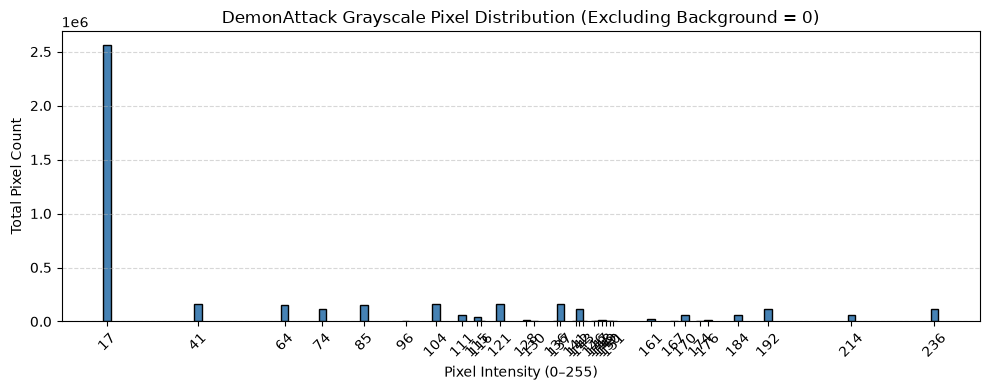

In [2]:

import gymnasium as gym
import ale_py
import numpy as np
import matplotlib.pyplot as plt

# 1. Initialize the environment
gym.register_envs(ale_py)
env = gym.make("ALE/DemonAttack-v5", obs_type="grayscale")
obs, _ = env.reset(seed=42)

# 2. Accumulate pixel counts across 1,000 steps (covering multiple waves/colors)
total_counts = np.zeros(256, dtype=np.int64)
num_steps = 1000

for _ in range(num_steps):
    obs, _, terminated, truncated, _ = env.step(env.action_space.sample())
    # bincount with minlength=256 returns exact frequency for every value 0..255
    total_counts += np.bincount(obs.ravel(), minlength=256)
    if terminated or truncated:
        obs, _ = env.reset()

env.close()

# 3. Print non-zero pixel value distribution
total_pixels = total_counts.sum()
print(f"{'Intensity':<10} | {'Pixel Count':<14} | {'Percentage':<10}")
print("-" * 40)
for val, count in enumerate(total_counts):
    if count > 0:
        pct = (count / total_pixels) * 100
        print(f"{val:<10} | {count:<14,} | {pct:>8.4f}%")

# 4. Plot the distribution (excluding 0 so active sprites are clearly visible)
non_zero_vals = np.where(total_counts > 0)[0]
non_zero_vals = non_zero_vals[non_zero_vals > 0]  # exclude background (0)

plt.figure(figsize=(10, 4))
plt.bar(non_zero_vals, total_counts[non_zero_vals], width=2.0, color="steelblue", edgecolor="black")
plt.title("DemonAttack Grayscale Pixel Distribution (Excluding Background = 0)")
plt.xlabel("Pixel Intensity (0–255)")
plt.ylabel("Total Pixel Count")
plt.xticks(non_zero_vals, rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Screen Region                      | Unique Non-Zero Intensities
----------------------------------------------------------------------
Background (most common)           | [17, 41, 64, 85, 96, 104, 115, 116, 121, 128, 137, 147, 148, 150, 161, 174, 176, 184]
HUD / Score (rows 0-25)            | [184]
Aliens & Bullets (rows 25-175)     | [96, 104, 115, 116, 128, 147, 148, 150, 174, 176]
Player Space Ship (rows 175-192)   | [85, 104, 115, 121, 137, 161]
Bottom Ground (rows 192-210)       | [17, 41, 64, 161]


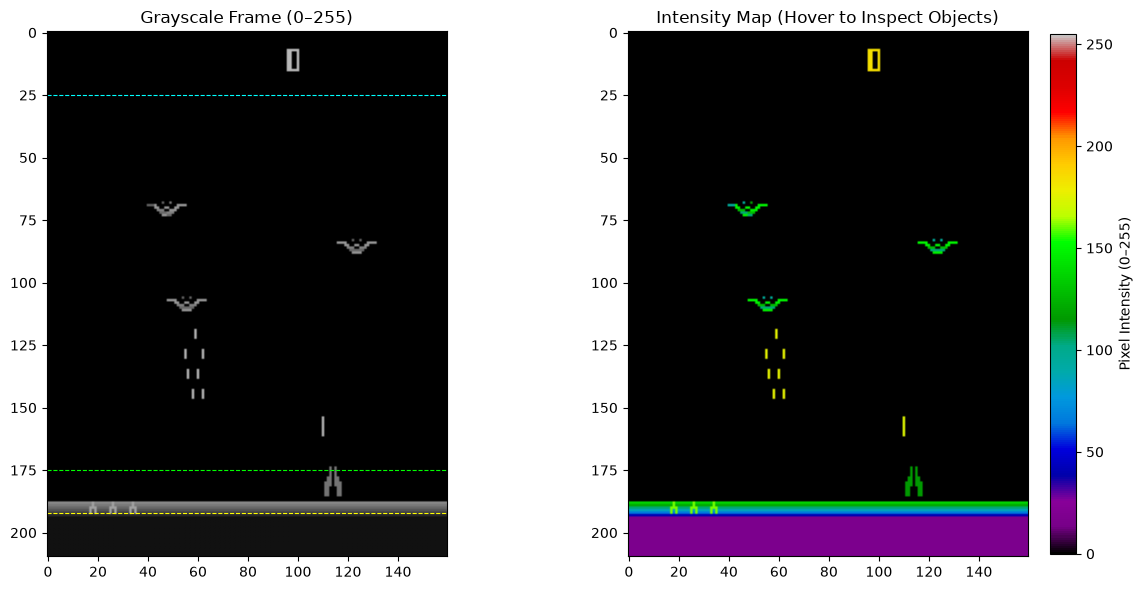

In [3]:
import gymnasium as gym
import ale_py
import numpy as np
import matplotlib.pyplot as plt

# 1. Initialize and step forward until bullets and enemies are on screen
gym.register_envs(ale_py)
env = gym.make("ALE/DemonAttack-v5", obs_type="grayscale")
obs, _ = env.reset(seed=42)

# Step ~60 frames and fire (action 1 = FIRE) so bullets and demons appear
for step in range(60):
    action = 1 if step % 5 == 0 else env.action_space.sample()
    obs, _, terminated, truncated, _ = env.step(action)
    if terminated or truncated:
        obs, _ = env.reset()

env.close()

# 2. Check exact intensities by vertical screen zone
zones = {
    "Background (most common)": obs,
    "HUD / Score (rows 0-25)": obs[0:25, :],
    "Aliens & Bullets (rows 25-175)": obs[25:175, :],
    "Player Space Ship (rows 175-192)": obs[175:192, :],
    "Bottom Ground (rows 192-210)": obs[192:210, :],
}

print(f"{'Screen Region':<34} | {'Unique Non-Zero Intensities'}")
print("-" * 70)
for name, region in zones.items():
    vals = np.unique(region)
    non_zero = vals[vals > 0]
    print(f"{name:<34} | {non_zero.tolist()}")

# 3. Visual Inspector: Hover your mouse over any bullet, ship, or alien to read its exact value
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Left: Raw grayscale image
axes[0].imshow(obs, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Grayscale Frame (0–255)")
axes[0].axhline(25, color="cyan", linestyle="--", linewidth=0.8)
axes[0].axhline(175, color="lime", linestyle="--", linewidth=0.8)
axes[0].axhline(192, color="yellow", linestyle="--", linewidth=0.8)

# Right: False-color map so every distinct intensity stands out clearly
im = axes[1].imshow(obs, cmap="nipy_spectral", vmin=0, vmax=255)
axes[1].set_title("Intensity Map (Hover to Inspect Objects)")
plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04, label="Pixel Intensity (0–255)")

plt.tight_layout()
plt.show()


Category / Screen Zone               | Pixel Type         |   Count | Ratio (of 33,600) | Intensities
-----------------------------------------------------------------------------------------------------
ENTIRE IMAGE (rows 0-210)            | Zero (Background)  |  29,873 |           88.91% | [0]
ENTIRE IMAGE (rows 0-210)            | Non-Zero (Objects) |   3,727 |           11.09% | [17, 41, 64, 85, 96, 104, 115, 116, 121, 128, 137, 147, 148, 150, 161, 174, 176, 184]
-----------------------------------------------------------------------------------------------------
HUD / Score (rows 0-25)              | Zero (Empty Space) |   3,969 |           11.81% | [0]
HUD / Score (rows 0-25)              | Non-Zero (Sprites) |      31 |            0.09% | [184]
-----------------------------------------------------------------------------------------------------
Aliens & Bullets (rows 25-175)       | Zero (Empty Space) |  23,866 |           71.03% | [0]
Aliens & Bullets (rows 25-175)       | Non-

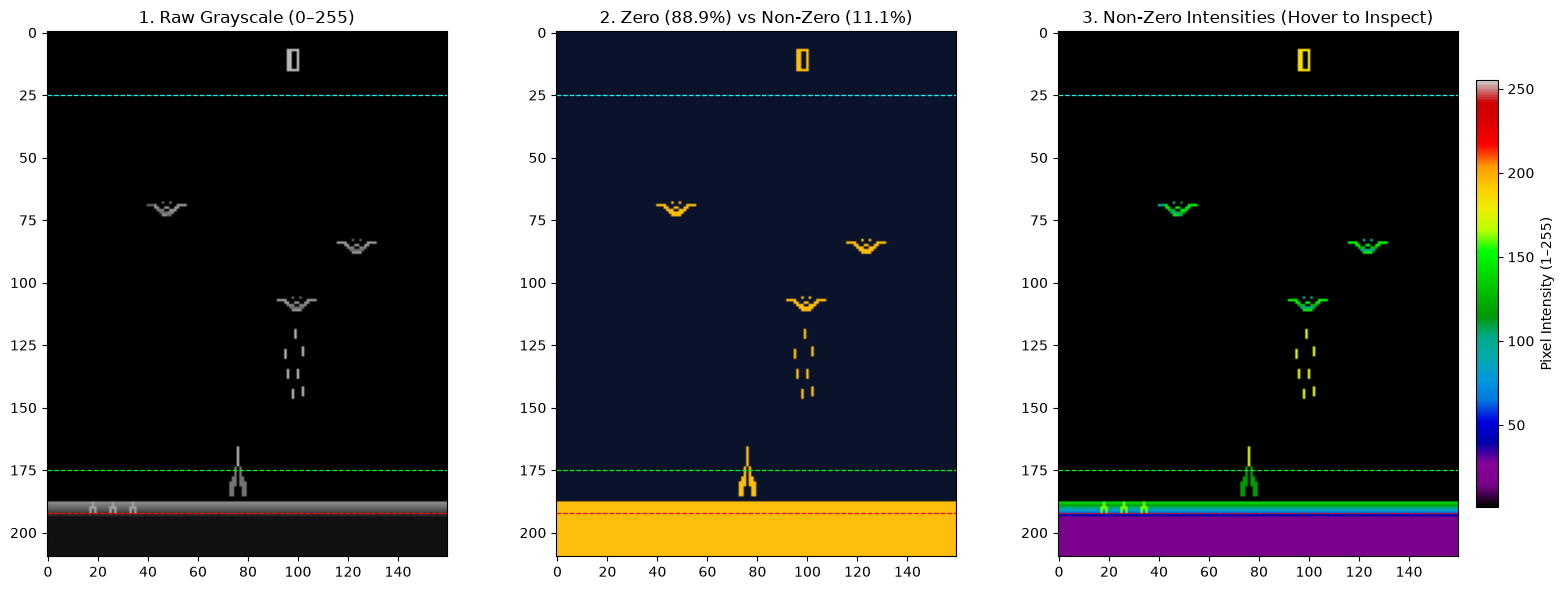

In [4]:
import gymnasium as gym
import ale_py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 1. Initialize and step forward until bullets and enemies are on screen
gym.register_envs(ale_py)
env = gym.make("ALE/DemonAttack-v5", obs_type="grayscale")
obs, _ = env.reset(seed=42)

# Step ~60 frames and fire (action 1 = FIRE) so bullets and demons appear
for step in range(60):
    action = 1 if step % 5 == 0 else env.action_space.sample()
    obs, _, terminated, truncated, _ = env.step(action)
    if terminated or truncated:
        obs, _ = env.reset()

env.close()

total_image_pixels = obs.size  # 210 * 160 = 33,600

# 2. Define screen zones
zones = {
    "HUD / Score (rows 0-25)": obs[0:25, :],
    "Aliens & Bullets (rows 25-175)": obs[25:175, :],
    "Player Space Ship (rows 175-192)": obs[175:192, :],
    "Bottom Ground (rows 192-210)": obs[192:210, :],
}

# 3. Print detailed breakdown for BOTH Zero (Background) and Non-Zero (Objects)
header = f"{'Category / Screen Zone':<36} | {'Pixel Type':<18} | {'Count':>7} | {'Ratio (of 33,600)':>17} | {'Intensities'}"
print(header)
print("-" * len(header))

# Overall image summary
total_zeros = int(np.sum(obs == 0))
total_nonzeros = int(np.sum(obs > 0))
print(f"{'ENTIRE IMAGE (rows 0-210)':<36} | {'Zero (Background)':<18} | {total_zeros:>7,} | {total_zeros / total_image_pixels:>16.2%} | [0]")
print(f"{'ENTIRE IMAGE (rows 0-210)':<36} | {'Non-Zero (Objects)':<18} | {total_nonzeros:>7,} | {total_nonzeros / total_image_pixels:>16.2%} | {np.unique(obs[obs > 0]).tolist()}")
print("-" * len(header))

# Zone-by-zone breakdown
for name, region in zones.items():
    zero_count = int(np.sum(region == 0))
    nonzero_count = int(np.sum(region > 0))
    nonzero_vals = np.unique(region[region > 0]).tolist()

    print(f"{name:<36} | {'Zero (Empty Space)':<18} | {zero_count:>7,} | {zero_count / total_image_pixels:>16.2%} | [0]")
    print(f"{name:<36} | {'Non-Zero (Sprites)':<18} | {nonzero_count:>7,} | {nonzero_count / total_image_pixels:>16.2%} | {nonzero_vals}")
    print("-" * len(header))

# 4. Visual Inspector: 3-Panel View (Grayscale, Binary Zero vs Non-Zero, Intensity Map)
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

# Panel 1: Raw grayscale image
axes[0].imshow(obs, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("1. Raw Grayscale (0–255)")

# Panel 2: Explicit Zero (Dark Navy) vs Non-Zero (Bright Gold) Mask
binary_mask = (obs > 0).astype(int)
binary_cmap = ListedColormap(["#0b132b", "#ffbe0b"])
axes[1].imshow(binary_mask, cmap=binary_cmap, vmin=0, vmax=1)
axes[1].set_title(f"2. Zero ({total_zeros/total_image_pixels:.1%}) vs Non-Zero ({total_nonzeros/total_image_pixels:.1%})")

# Panel 3: False-color intensity map (0 set to black so active sprites pop)
cmap_intensity = plt.get_cmap("nipy_spectral").copy()
cmap_intensity.set_under("black")
im = axes[2].imshow(obs, cmap=cmap_intensity, vmin=1, vmax=255)
axes[2].set_title("3. Non-Zero Intensities (Hover to Inspect)")
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04, label="Pixel Intensity (1–255)")

# Draw zone boundary lines across all 3 panels
for ax in axes:
    ax.axhline(25, color="cyan", linestyle="--", linewidth=0.9)
    ax.axhline(175, color="lime", linestyle="--", linewidth=0.9)
    ax.axhline(192, color="red", linestyle="--", linewidth=0.9)

plt.tight_layout()
plt.show()
